Estado Inicial: [ 2.10396343e+03 -6.35883874e+03  1.12878601e+03  4.28137832e+00
  2.46835746e+00  5.86343808e+00]
Integração sem perturbações concluída em 2502 passos.
Integração com arrasto concluída em 2502 passos.
Integração com J2 concluída em 2502 passos.
Integração com arrasto e J2 concluída em 2502 passos.
Erro Numérico sem Perturbações: 0.002166500453313347
Erro Numérico com Arrasto: 0.08932800941693131
Erro Numérico com J2: 45.59438777780451
Erro Numérico com Arrasto e J2: 45.668657854730554


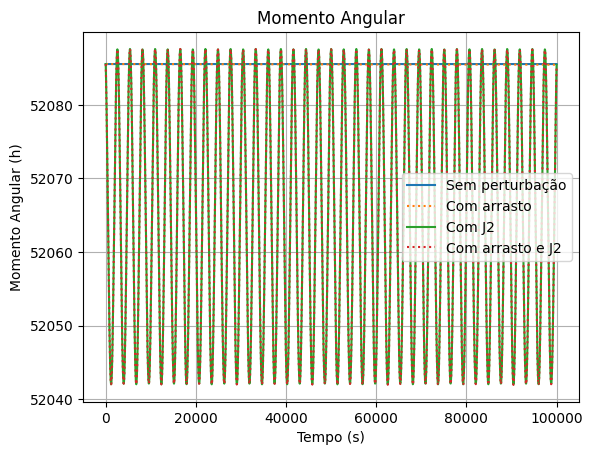

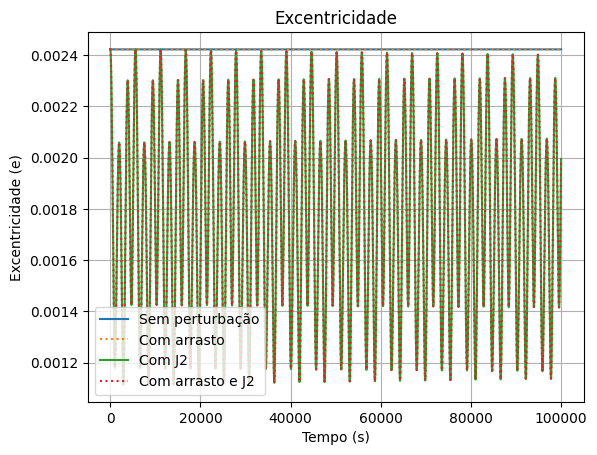

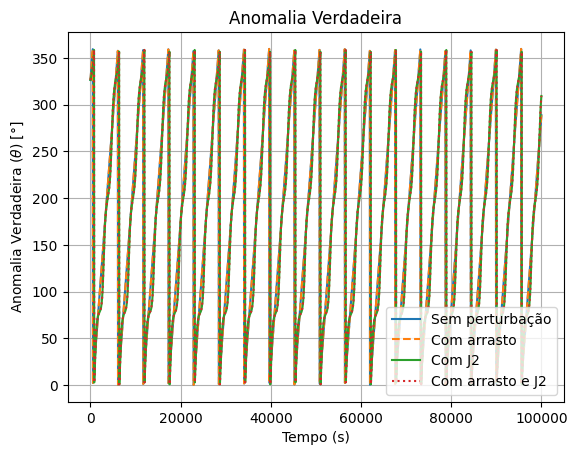

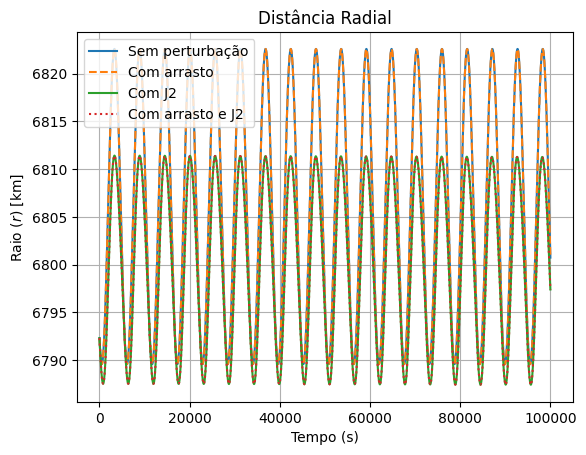

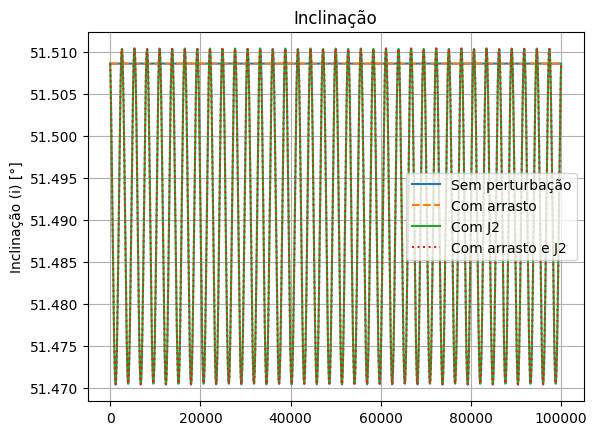

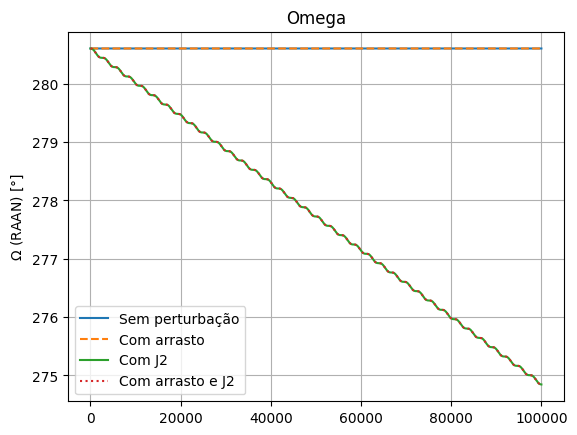

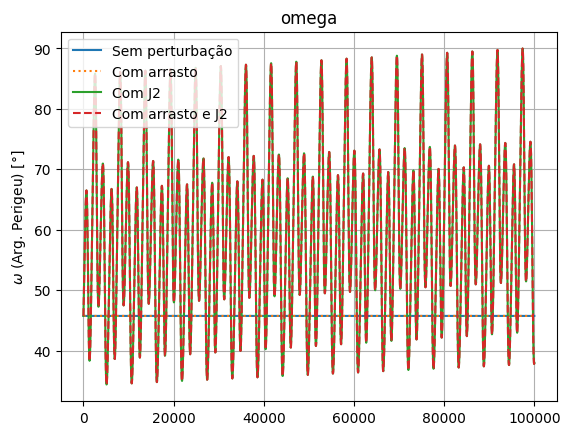

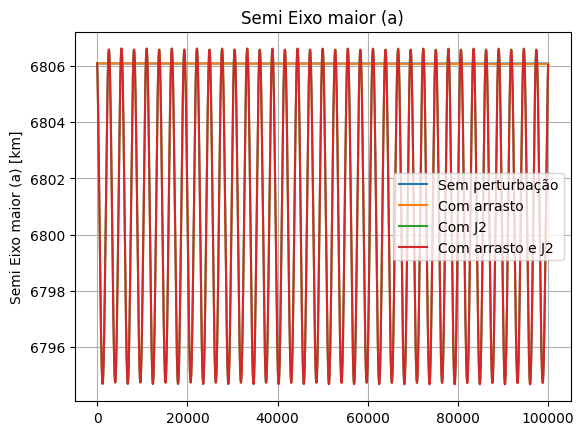

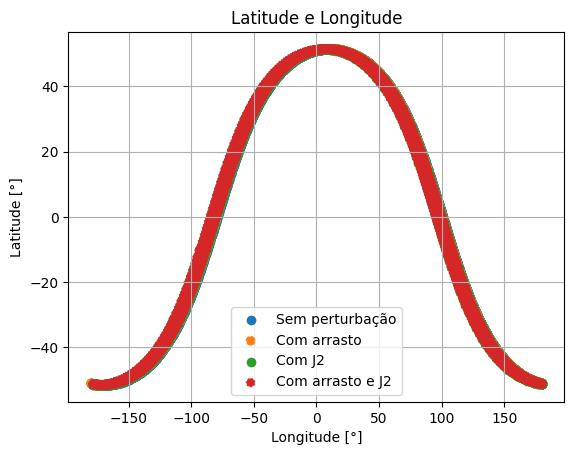

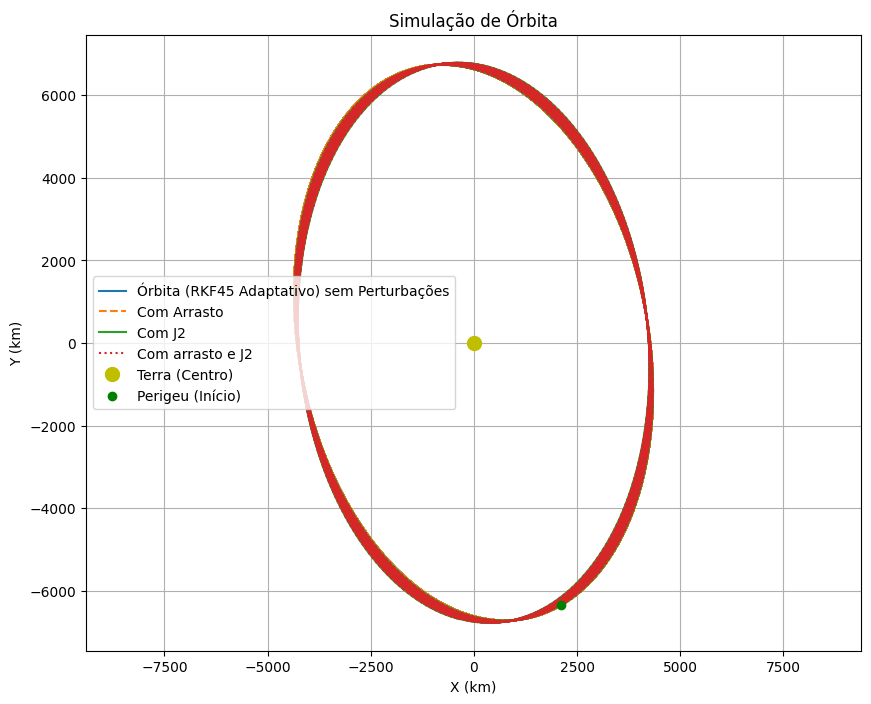

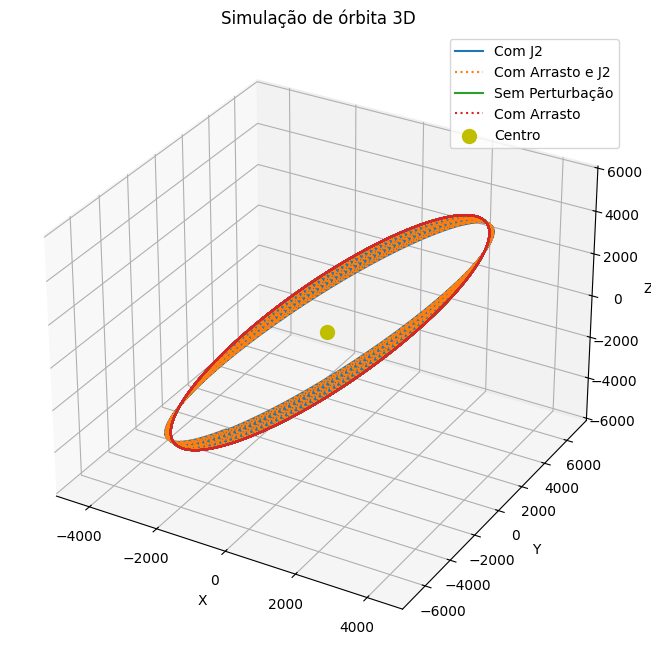

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Estado inicial
MU = 398601.87717000005
x_init = 2103.963425777700
y_init = -6358.838741164520
z_init = 1128.786006468580
v_x_init = 4.28137831609971
v_y_init = 2.46835745541399
v_z_init = 5.86343807843212

u0 = np.array([x_init, y_init, z_init, v_x_init, v_y_init, v_z_init])

R_P = u0[:3]
V_P = u0[3:]
T_MAX = 100000
h_teorico = np.linalg.norm(np.cross(R_P, V_P))
print(f"Estado Inicial: {u0}")

# Parâmetros de Arrasto para a ISS (Exemplos)
CD = 2.6         # Coeficiente de arrasto típico
AREA = 1211.10/4    # Área em m^2 (ISS é grande)
MASSA = 450000.0 # Massa em kg
RHO = 2.5e-12      # Densidade atmosférica simplificada em kg/m^3 a ~400km

# Parâmetros para o J2
J2 = 0.00108263      # Coeficiente de achatamento
R_EARTH = 6378.137   # Raio equatorial da Terra em km

# Aceleração sem perturbações
def acceleration_3d_0(x, t):
    r_vec_0 = x[:3]
    v_vec_0 = x[3:]
    r_norm_0 = np.linalg.norm(r_vec_0)
    if r_norm_0 == 0: raise ValueError("Colisão!")
    a_vec_0 = -MU * r_vec_0 / (r_norm_0**3)
    return np.concatenate((v_vec_0, a_vec_0))

# Aceleração com arrasto
def acceleration_3d_drag(x, t):
    r_vec_drag = x[:3]
    v_vec_drag = x[3:]
    r_norm_drag = np.linalg.norm(r_vec_drag)
    v_norm_drag = np.linalg.norm(v_vec_drag)

    if r_norm_drag == 0: raise ValueError("Colisão!")

    # Aceleração Gravitacional (Central)
    a_grav = -MU * r_vec_drag / (r_norm_drag**3)

    # Aceleração de Arrasto (Perturbação)
    # Importante: converter AREA para km² se MU e r estiverem em km
    # Ou converter r e MU para metros. Vamos manter km:
    area_km2 = AREA / 1e6
    massa_kg = MASSA
    rho_kg_km3 = RHO * 1e9 # Convertendo kg/m³ para kg/km³

    # Cálculo do módulo do arrasto
    # A fórmula simplificada: a = -0.5 * (CD * A / m) * rho * v^2 * unit_v
    drag_mag = 0.5 * (CD * area_km2 / massa_kg) * rho_kg_km3 * (v_norm_drag**2)
    a_drag = -drag_mag * (v_vec_drag / v_norm_drag)

    # Aceleração Total
    return np.concatenate((v_vec_drag, a_grav + a_drag))

# Aceleração com J2
def acceleration_3d_J2(x, t):
    r_vec_J2 = x[:3]
    v_vec_J2 = x[3:]
    r_norm_J2 = np.linalg.norm(r_vec_J2)
    v_norm_J2 = np.linalg.norm(v_vec_J2)

    if r_norm_J2 == 0: raise ValueError("Colisão!")

    # Aceleração Gravitacional Central
    a_grav_J2 = -MU * r_vec_J2 / (r_norm_J2**3)

    #  Perturbação J2
    # Fator comum da aceleração J2
    z2 = r_vec_J2[2]**2
    r2 = r_norm_J2**2
    factor = (3/2) * J2 * (MU * R_EARTH**2 / r_norm_J2**5)

    ax_j2 = factor * r_vec_J2[0] * (5 * (z2 / r2) - 1)
    ay_j2 = factor * r_vec_J2[1] * (5 * (z2 / r2) - 1)
    az_j2 = factor * r_vec_J2[2] * (5 * (z2 / r2) - 3)

    a_j2 = np.array([ax_j2, ay_j2, az_j2])


    # Aceleração Total
    return np.concatenate((v_vec_J2, a_grav_J2 + a_j2))

# Aceleração com Arrasto e J2
def acceleration_3d_dragJ2(x, t):
    r_vec_dragJ2 = x[:3]
    v_vec_dragJ2 = x[3:]
    r_norm_dragJ2 = np.linalg.norm(r_vec_dragJ2)
    v_norm_dragJ2 = np.linalg.norm(v_vec_dragJ2)

    if r_norm_dragJ2 == 0: raise ValueError("Colisão!")

    # Aceleração Gravitacional Central
    a_grav_dragJ2 = -MU * r_vec_dragJ2 / (r_norm_dragJ2**3)

    # Perturbação J2
    # Fator comum da aceleração J2
    z2_dragJ2 = r_vec_dragJ2[2]**2
    r2_dragJ2 = r_norm_dragJ2**2
    factor_dragJ2 = (3/2) * J2 * (MU * R_EARTH**2 / r_norm_dragJ2**5)

    ax_j2 = factor_dragJ2 * r_vec_dragJ2[0] * (5 * (z2_dragJ2 / r2_dragJ2) - 1)
    ay_j2 = factor_dragJ2 * r_vec_dragJ2[1] * (5 * (z2_dragJ2 / r2_dragJ2) - 1)
    az_j2 = factor_dragJ2 * r_vec_dragJ2[2] * (5 * (z2_dragJ2 / r2_dragJ2) - 3)

    a_j2 = np.array([ax_j2, ay_j2, az_j2])

    # Aceleração de Arrasto
    area_km2 = AREA / 1e6
    rho_kg_km3 = RHO * 1e9
    drag_mag = 0.5 * (CD * area_km2 / MASSA) * rho_kg_km3 * (v_norm_dragJ2**2)
    a_dragJ2 = -drag_mag * (v_vec_dragJ2 / v_norm_dragJ2)

    # Aceleração Total
    return np.concatenate((v_vec_dragJ2, a_grav_dragJ2 + a_j2 + a_dragJ2))

# Runge Kutta
def runge_kutta_fehlberg(g, x, t, h):
    x = x.astype(float)
    k1 = h * g(x, t)
    k2 = h * g(x + k1 / 4.0, t + h / 4.0)
    k3 = h * g(x + 3.0 * k1 / 32.0 + 9.0 * k2 / 32.0, t + 3.0 * h / 8.0)
    k4 = h * g(x + 1932.0 * k1 / 2197.0 - 7200.0 * k2 / 2197.0 + 7296.0 * k3 / 2197.0, t + 12.0 * h / 13.0)
    k5 = h * g(x + 439.0 * k1 / 216.0 - 8.0 * k2 + 3680.0 * k3 / 513.0 - 845.0 * k4 / 4104.0, t + h)
    k6 = h * g(x - 8.0 * k1 / 27.0 + 2 * k2 - 3544.0 * k3 / 2565 + 1859.0 * k4 / 4104.0 - 11.0 * k5 / 40.0, t + h / 2.0)
    w = x + 25.0 * k1 / 216.0 + 1408.0 * k3 / 2565.0 + 2197.0 * k4 / 4104.0 - k5 / 5.0
    q = x + 16.0 * k1 / 135.0 + 6656.0 * k3 / 12825.0 + 28561.0 * k4 / 56430.0 - 9.0 * k5 / 50.0 + 2.0 * k6 / 55.0
    return w, q

def rk_adaptive(ode, rhs, y0, t0=0.0, TOL=1e-9, theta=1e-8, tmax=1.0):
    y, t = [np.array(y0)], [t0]
    h = 10.0
    i = 0 # Initialize iteration counter
    while t[-1] < tmax:
        w, q = ode(rhs, y[-1], t[-1], h)
        diff = np.linalg.norm(w - q)
        scale = max(np.linalg.norm(y[-1]), 1e-8)
        err = diff / scale
        if err > TOL:
            h = 0.9 * h * (TOL / err)**0.2
            continue
        y.append(q)
        t.append(t[-1] + h)
        i += 1 # Increment iteration counter
        if err < 0.1 * TOL: h *= 2.0
        if t[-1] + h > tmax: h = tmax - t[-1]
    return np.array(y), np.array(t), i # Return i as well

# Execução da Integração sem perturbações
pos_0, times, iterations_0 = rk_adaptive(runge_kutta_fehlberg, acceleration_3d_0, y0=u0, t0=0.0, TOL=1e-9, theta=1e-8, tmax=T_MAX)
print(f"Integração sem perturbações concluída em {iterations_0} passos.")

# Execução da Integração com arrasto
pos_drag, times, iterations_drag = rk_adaptive(runge_kutta_fehlberg, acceleration_3d_drag, y0=u0, t0=0.0, TOL=1e-9, theta=1e-8, tmax=T_MAX)
print(f"Integração com arrasto concluída em {iterations_drag} passos.")

# Execução da Integração com J2
pos_J2, times, iterations_J2 = rk_adaptive(runge_kutta_fehlberg, acceleration_3d_J2, y0=u0, t0=0.0, TOL=1e-9, theta=1e-8, tmax=T_MAX)
print(f"Integração com J2 concluída em {iterations_J2} passos.")

# Execução da Integração com arrasto e J2
pos_dragJ2, times, iterations_dragJ2 = rk_adaptive(runge_kutta_fehlberg, acceleration_3d_dragJ2, y0=u0, t0=0.0, TOL=1e-9, theta=1e-8, tmax=T_MAX)
print(f"Integração com arrasto e J2 concluída em {iterations_dragJ2} passos.")

# Processamento de todos os Parâmetros sem perturbações
r_mags_0, h_mags_0, e_mags_0, nu_list_0, p_0, a_0 = [], [], [], [], [], []
incs_0, big_omegas_0, small_omegas_0 = [], [], []
K_0 = np.array([0, 0, 1])

for state in pos_0:
    rv_0, vv_0 = state[:3], state[3:]
    rm_0 = np.linalg.norm(rv_0)
    hv_0 = np.cross(rv_0, vv_0)
    hm_0 = np.linalg.norm(hv_0)
    ev_0 = (np.cross(vv_0, hv_0) / MU) - (rv_0 / rm_0)
    em_0 = np.linalg.norm(ev_0)


    # Magnitudes
    r_mags_0.append(rm_0)
    h_mags_0.append(hm_0)
    e_mags_0.append(em_0)

    # Anomalia Verdadeira (theta)
    cp_0 = np.clip(((hm_0**2 / (MU * rm_0)) - 1.0) / em_0, -1, 1)
    theta = np.arccos(cp_0)
    if np.dot(rv_0, vv_0) < 0: theta = 2 * np.pi - theta
    nu_list_0.append(np.degrees(theta))

    # Inclinação (i)
    incs_0.append(np.degrees(np.arccos(np.clip(hv_0[2]/hm_0, -1, 1))))

    # Big Omega (RAAN)
    nv_0 = np.cross(K_0, hv_0)
    nm_0 = np.linalg.norm(nv_0)
    if nm_0 != 0:
        Omega_0 = np.arccos(np.clip(nv_0[0]/nm_0, -1, 1))
        if nv_0[1] < 0: Omega_0 = 2 * np.pi - Omega_0
        big_omegas_0.append(np.degrees(Omega_0))
    else:
        big_omegas_0.append(0.0)

    # Small Omega (Arg. Perigeu)
    if nm_0 != 0 and em_0 > 1e-12:
        w_rad_0 = np.arccos(np.clip(np.dot(nv_0, ev_0)/(nm_0*em_0), -1, 1))
        if ev_0[2] < 0: w_rad_0 = 2 * np.pi - w_rad_0
        small_omegas_0.append(np.degrees(w_rad_0))
    else:
        small_omegas_0.append(0.0)

    # Semilatus Rectum (p)
    p_mag_0 = (hm_0**2 / MU)

    p_0.append(p_mag_0)

    # Semi eixo maior (a)
    a_mag_0 = (p_mag_0 / (1 - em_0**2))

    a_0.append(a_mag_0)

# Erro Numérico
minimo_0 = min(h_mags_0)
maximo_0 = max(h_mags_0)
erro_numerico_0 = maximo_0 - minimo_0
print(f"Erro Numérico sem Perturbações: {erro_numerico_0}")

# Processamento de todos os Parâmetros com arrasto
r_mags_drag, h_mags_drag, e_mags_drag, nu_list_drag, p_drag, a_drag = [], [], [], [], [], []
incs_drag, big_omegas_drag, small_omegas_drag = [], [], []
K_drag = np.array([0, 0, 1])

for state in pos_drag:
    rv_drag, vv_drag = state[:3], state[3:]
    rm_drag = np.linalg.norm(rv_drag)
    hv_drag = np.cross(rv_drag, vv_drag)
    hm_drag = np.linalg.norm(hv_drag)
    ev_drag = (np.cross(vv_drag, hv_drag) / MU) - (rv_drag / rm_drag)
    em_drag = np.linalg.norm(ev_drag)


    # Magnitudes
    r_mags_drag.append(rm_drag)
    h_mags_drag.append(hm_drag)
    e_mags_drag.append(em_drag)

    # Anomalia Verdadeira (theta)
    cp_drag = np.clip(((hm_drag**2 / (MU * rm_drag)) - 1.0) / em_drag, -1, 1)
    theta_drag = np.arccos(cp_drag)
    if np.dot(rv_drag, vv_drag) < 0: theta_drag = 2 * np.pi - theta_drag
    nu_list_drag.append(np.degrees(theta_drag))

    # Inclinação (i)
    incs_drag.append(np.degrees(np.arccos(np.clip(hv_drag[2]/hm_drag, -1, 1))))

    # Big Omega (RAAN)
    nv_drag = np.cross(K_drag, hv_drag)
    nm_drag = np.linalg.norm(nv_drag)
    if nm_drag != 0:
        Omega_drag = np.arccos(np.clip(nv_drag[0]/nm_drag, -1, 1))
        if nv_drag[1] < 0: Omega_drag = 2 * np.pi - Omega_drag
        big_omegas_drag.append(np.degrees(Omega_drag))
    else:
        big_omegas_drag.append(0.0)

    # Small Omega (Arg. Perigeu)
    if nm_drag != 0 and em_drag > 1e-12:
        w_rad_drag = np.arccos(np.clip(np.dot(nv_drag, ev_drag)/(nm_drag*em_drag), -1, 1))
        if ev_drag[2] < 0: w_rad_drag = 2 * np.pi - w_rad_drag
        small_omegas_drag.append(np.degrees(w_rad_drag))
    else:
        small_omegas_drag.append(0.0)

    # Semilatus Rectum (p)
    p_mag_drag = (hm_drag**2 / MU)

    p_drag.append(p_mag_drag)

    # Semi eixo maior (a)
    a_mag_drag = (p_mag_drag / (1 - em_drag**2))

    a_drag.append(a_mag_drag)

# Erro Numérico
minimo_drag = min(h_mags_drag)
maximo_drag = max(h_mags_drag)
erro_numerico_drag = maximo_drag - minimo_drag
print(f"Erro Numérico com Arrasto: {erro_numerico_drag}")

# Processamento de todos os Parâmetros com J2
r_mags_J2, h_mags_J2, e_mags_J2, nu_list_J2, p_J2, a_J2 = [], [], [], [], [], []
incs_J2, big_omegas_J2, small_omegas_J2 = [], [], []
K_J2 = np.array([0, 0, 1])

for state in pos_J2:
    rv_J2, vv_J2 = state[:3], state[3:]
    rm_J2 = np.linalg.norm(rv_J2)
    hv_J2 = np.cross(rv_J2, vv_J2)
    hm_J2 = np.linalg.norm(hv_J2)
    ev_J2 = (np.cross(vv_J2, hv_J2) / MU) - (rv_J2 / rm_J2)
    em_J2 = np.linalg.norm(ev_J2)


    # Magnitudes
    r_mags_J2.append(rm_J2)
    h_mags_J2.append(hm_J2)
    e_mags_J2.append(em_J2)

    # Anomalia Verdadeira (theta)
    cp_J2 = np.clip(((hm_J2**2 / (MU * rm_J2)) - 1.0) / em_J2, -1, 1)
    theta_J2 = np.arccos(cp_J2)
    if np.dot(rv_J2, vv_J2) < 0: theta_J2 = 2 * np.pi - theta_J2
    nu_list_J2.append(np.degrees(theta_J2))

    # Inclinação (i)
    incs_J2.append(np.degrees(np.arccos(np.clip(hv_J2[2]/hm_J2, -1, 1))))

    # Big Omega (RAAN)
    nv_J2 = np.cross(K_J2, hv_J2)
    nm_J2 = np.linalg.norm(nv_J2)
    if nm_J2 != 0:
        Omega_J2 = np.arccos(np.clip(nv_J2[0]/nm_J2, -1, 1))
        if nv_J2[1] < 0: Omega_J2 = 2 * np.pi - Omega_J2
        big_omegas_J2.append(np.degrees(Omega_J2))
    else:
        big_omegas_J2.append(0.0)

    # Small Omega (Arg. Perigeu)
    if nm_J2 != 0 and em_J2 > 1e-12:
        w_rad_J2 = np.arccos(np.clip(np.dot(nv_J2, ev_J2)/(nm_J2*em_J2), -1, 1))
        if ev_J2[2] < 0: w_rad_J2 = 2 * np.pi - w_rad_J2
        small_omegas_J2.append(np.degrees(w_rad_J2))
    else:
        small_omegas_J2.append(0.0)

    # Semilatus Rectum (p)
    p_mag_J2 = (hm_J2**2 / MU)

    p_J2.append(p_mag_J2)

    # Semi eixo maior (a)
    a_mag_J2 = (p_mag_J2 / (1 - em_J2**2))

    a_J2.append(a_mag_J2)

# Erro Numérico
minimo_J2 = min(h_mags_J2)
maximo_J2 = max(h_mags_J2)
erro_numerico_J2 = maximo_J2 - minimo_J2
print(f"Erro Numérico com J2: {erro_numerico_J2}")

# Processamento de todos os Parâmetros com arrasto e J2
r_mags_dragJ2, h_mags_dragJ2, e_mags_dragJ2, nu_list_dragJ2, p_dragJ2, a_dragJ2 = [], [], [], [], [], []
incs_dragJ2, big_omegas_dragJ2, small_omegas_dragJ2 = [], [], []
K_dragJ2 = np.array([0, 0, 1])

for state in pos_dragJ2:
    rv_dragJ2, vv_dragJ2 = state[:3], state[3:]
    rm_dragJ2 = np.linalg.norm(rv_dragJ2)
    hv_dragJ2 = np.cross(rv_dragJ2, vv_dragJ2)
    hm_dragJ2 = np.linalg.norm(hv_dragJ2)
    ev_dragJ2 = (np.cross(vv_dragJ2, hv_dragJ2) / MU) - (rv_dragJ2 / rm_dragJ2)
    em_dragJ2 = np.linalg.norm(ev_dragJ2)


    # Magnitudes
    r_mags_dragJ2.append(rm_dragJ2)
    h_mags_dragJ2.append(hm_dragJ2)
    e_mags_dragJ2.append(em_dragJ2)

    # Anomalia Verdadeira (theta)
    cp_dragJ2 = np.clip(((hm_dragJ2**2 / (MU * rm_dragJ2)) - 1.0) / em_dragJ2, -1, 1)
    theta_dragJ2 = np.arccos(cp_dragJ2)
    if np.dot(rv_dragJ2, vv_dragJ2) < 0: theta_dragJ2 = 2 * np.pi - theta_dragJ2
    nu_list_dragJ2.append(np.degrees(theta_dragJ2))

    # Inclinação (i)
    incs_dragJ2.append(np.degrees(np.arccos(np.clip(hv_dragJ2[2]/hm_dragJ2, -1, 1))))

    # Big Omega (RAAN)
    nv_dragJ2 = np.cross(K_dragJ2, hv_dragJ2)
    nm_dragJ2 = np.linalg.norm(nv_dragJ2)
    if nm_dragJ2 != 0:
        Omega_dragJ2 = np.arccos(np.clip(nv_dragJ2[0]/nm_dragJ2, -1, 1))
        if nv_dragJ2[1] < 0: Omega_dragJ2 = 2 * np.pi - Omega_dragJ2
        big_omegas_dragJ2.append(np.degrees(Omega_dragJ2))
    else:
        big_omegas_dragJ2.append(0.0)

    # Small Omega (Arg. Perigeu)
    if nm_dragJ2 != 0 and em_dragJ2 > 1e-12:
        w_rad_dragJ2 = np.arccos(np.clip(np.dot(nv_dragJ2, ev_dragJ2)/(nm_dragJ2*em_dragJ2), -1, 1))
        if ev_dragJ2[2] < 0: w_rad_dragJ2 = 2 * np.pi - w_rad_dragJ2
        small_omegas_dragJ2.append(np.degrees(w_rad_dragJ2))
    else:
        small_omegas_dragJ2.append(0.0)

    # Semilatus Rectum (p)
    p_mag_dragJ2 = (hm_dragJ2**2 / MU)

    p_dragJ2.append(p_mag_dragJ2)

    # Semi eixo maior (a)
    a_mag_dragJ2 = (p_mag_dragJ2 / (1 - em_dragJ2**2))

    a_dragJ2.append(a_mag_dragJ2)

# Erro Numérico
minimo_dragJ2 = min(h_mags_dragJ2)
maximo_dragJ2 = max(h_mags_dragJ2)
erro_numerico_dragJ2 = maximo_dragJ2 - minimo_dragJ2
print(f"Erro Numérico com Arrasto e J2: {erro_numerico_dragJ2}")

# Extração de Dados para Plotagem sem perturbação
x_0 = pos_0[:, 0]
y_0 = pos_0[:, 1]
z_0 = pos_0[:, 2]

# Extração de Dados para Plotagem com Arrasto
x_drag = pos_drag[:, 0]
y_drag = pos_drag[:, 1]
z_drag = pos_drag[:, 2]

# Extração de Dados para Plotagem
x_J2 = pos_J2[:, 0]
y_J2 = pos_J2[:, 1]
z_J2 = pos_J2[:, 2]

# Extração de Dados para Plotagem com Arrasto e J2
x_dragJ2 = pos_dragJ2[:, 0]
y_dragJ2 = pos_dragJ2[:, 1]
z_dragJ2 = pos_dragJ2[:, 2]

# Função para converter Cartesiano para esférico sem perturbação
latitudes_0 = np.degrees(np.arcsin(z_0 / r_mags_0))
longitudes_0 = np.degrees(np.arctan2(y_0, x_0))

# Função para converter Cartesiano para esférico com arrasto
latitudes_drag = np.degrees(np.arcsin(z_drag / r_mags_drag))
longitudes_drag = np.degrees(np.arctan2(y_drag, x_drag))

# Função para converter Cartesiano para esférico com J2
latitudes_J2 = np.degrees(np.arcsin(z_J2 / r_mags_J2))
longitudes_J2 = np.degrees(np.arctan2(y_J2, x_J2))

# Função para converter Cartesiano para esférico com Arrasto e J2
latitudes_dragJ2 = np.degrees(np.arcsin(z_dragJ2 / r_mags_dragJ2))
longitudes_dragJ2 = np.degrees(np.arctan2(y_dragJ2, x_dragJ2))

# Plotagem

# Momento Angular e Excentricidade
plt.plot(times, h_mags_0, label='Sem perturbação')
plt.plot(times, h_mags_drag,linestyle = ':', label='Com arrasto')
plt.plot(times, h_mags_J2, label = 'Com J2')
plt.plot(times, h_mags_dragJ2,linestyle = ':', label = 'Com arrasto e J2')
plt.grid(True)
plt.xlabel('Tempo (s)')
plt.ylabel('Momento Angular (h)')
plt.legend()
plt.title('Momento Angular')
plt.show()

plt.plot(times, e_mags_0, label = 'Sem perturbação')
plt.plot(times, e_mags_drag,linestyle = ':', label = 'Com arrasto')
plt.plot(times, e_mags_J2, label = 'Com J2')
plt.plot(times, e_mags_dragJ2,linestyle = ':', label = 'Com arrasto e J2')
plt.grid(True)
plt.xlabel('Tempo (s)')
plt.ylabel('Excentricidade (e)')
plt.legend()
plt.title('Excentricidade')
plt.show()

# Anomalia Verdadeira e Raio
plt.plot(times, nu_list_0, label = 'Sem perturbação')
plt.plot(times, nu_list_drag, linestyle = '--', label = 'Com arrasto')
plt.plot(times, nu_list_J2, label = 'Com J2')
plt.plot(times, nu_list_dragJ2,linestyle = ':', label = 'Com arrasto e J2')
plt.grid(True)
plt.xlabel('Tempo (s)')
plt.ylabel('Anomalia Verdadeira ($\\theta$) [°]')
plt.legend()
plt.title('Anomalia Verdadeira')
plt.show()

plt.plot(times, r_mags_0, label = 'Sem perturbação')
plt.plot(times, r_mags_drag, linestyle = '--', label = 'Com arrasto')
plt.plot(times, r_mags_J2, label = 'Com J2')
plt.plot(times, r_mags_dragJ2,linestyle = ':', label = 'Com arrasto e J2')
plt.grid(True)
plt.xlabel('Tempo (s)')
plt.ylabel('Raio ($r$) [km]')
plt.legend()
plt.title('Distância Radial')
plt.show()

# Elementos de orientação (i, Omega, omega)
plt.plot(times, incs_0, label = 'Sem perturbação')
plt.plot(times, incs_drag, linestyle = '--', label = 'Com arrasto')
plt.plot(times, incs_J2, label = 'Com J2')
plt.plot(times, incs_dragJ2,linestyle = ':', label = 'Com arrasto e J2')
plt.grid(True)
plt.ylabel('Inclinação (i) [°]')
plt.legend()
plt.title('Inclinação')
plt.show()

plt.plot(times, big_omegas_0, label = 'Sem perturbação')
plt.plot(times, big_omegas_drag, linestyle = '--',label = 'Com arrasto')
plt.plot(times, big_omegas_J2, label = 'Com J2')
plt.plot(times, big_omegas_dragJ2, linestyle = ':', label = 'Com arrasto e J2')
plt.grid(True)
plt.title('Omega')
plt.legend()
plt.ylabel('$\\Omega$ (RAAN) [°]')
plt.show()

plt.plot(times, small_omegas_0, label = 'Sem perturbação')
plt.plot(times, small_omegas_drag,linestyle=":", label = 'Com arrasto')
plt.plot(times, small_omegas_J2, label = 'Com J2')
plt.plot(times, small_omegas_dragJ2, linestyle = '--', label = 'Com arrasto e J2')
plt.grid(True)
plt.title('omega')
plt.legend()
plt.ylabel('$\\omega$ (Arg. Perigeu) [°]')
plt.show()

# Semi-eixo maior
plt.plot(times, a_0, label = 'Sem perturbação')
plt.plot(times, a_drag,linestyle = '-', label = 'Com arrasto')
plt.plot(times, a_J2, label = 'Com J2')
plt.plot(times, a_dragJ2,linestyle = '-', label = 'Com arrasto e J2')
plt.grid(True)
plt.title('Semi Eixo maior (a)')
plt.legend()
plt.ylabel('Semi Eixo maior (a) [km]')
plt.show()

# Longitude e Latitude
plt.scatter(longitudes_0, latitudes_0, label = 'Sem perturbação' )
plt.scatter(longitudes_drag, latitudes_drag, linestyle = '--', label = 'Com arrasto')
plt.scatter(longitudes_J2, latitudes_J2, label = 'Com J2')
plt.scatter(longitudes_dragJ2, latitudes_dragJ2,linestyle = ':', label ='Com arrasto e J2')
plt.grid(True)
plt.xlabel('Longitude [°]')
plt.ylabel('Latitude [°]')
plt.legend()
plt.title('Latitude e Longitude')

# Plotagem Básica 2D
plt.figure(figsize=(10, 8))
plt.plot(x_0, y_0, label='Órbita (RKF45 Adaptativo) sem Perturbações')
plt.plot(x_drag, y_drag, linestyle = '--', label = 'Com Arrasto')
plt.plot(x_J2, y_J2, label = 'Com J2')
plt.plot(x_dragJ2, y_dragJ2,linestyle = ':', label = 'Com arrasto e J2')
plt.plot(0, 0, 'yo', markersize=10, label='Terra (Centro)') # Centro
plt.plot(x_0[0], y_0[0], 'go', label='Perigeu (Início)')
plt.axis('equal')
plt.grid(True)
plt.xlabel('X (km)')
plt.ylabel('Y (km)')
plt.title('Simulação de Órbita')
plt.legend()
plt.show()

# Plotagem 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x_J2, y_J2, z_J2, label = 'Com J2', linestyle = "-")
ax.plot(x_dragJ2, y_dragJ2, z_dragJ2, label = 'Com Arrasto e J2', linestyle = ':')
ax.plot(x_0, y_0, z_0, label='Sem Perturbação', linestyle = "-")
ax.plot(x_drag, y_drag, z_drag, label = 'Com Arrasto', linestyle = ':')
ax.scatter([0], [0], [0], color='y', s=100, label='Centro')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Simulação de órbita 3D')
ax.legend()
plt.show()